In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from itertools import islice

In [2]:
path = r"../Datas/online+retail/dt.xlsx"
df = pd.read_excel(path)
display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## EDA

In [3]:
display(df.head())
print("Ukuran dataset:", df.shape)
display(df.info())
display(df.describe())
display(df.duplicated().sum())
display(df.isna().sum())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Ukuran dataset: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


None

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


np.int64(5268)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:
# 1. Aggregate unique counts per InvoiceNo
invoice_check = df.groupby('InvoiceNo').agg(
    date_count=('InvoiceDate', 'nunique'),
    customer_count=('CustomerID', lambda x: x.nunique(dropna=False))
)

# 2. Filter for InvoiceNos with more than 1 unique date OR customer ID
mismatched_invoices = invoice_check[
    (invoice_check['date_count'] > 1) | (invoice_check['customer_count'] > 1)
]

print(f"Total mismatched InvoiceNos: {len(mismatched_invoices)}")
display(mismatched_invoices)

# 3. Display full records (Cast InvoiceNo to str & CustomerID to Int64)
mismatched_df = df[df['InvoiceNo'].isin(mismatched_invoices.index)].copy()
mismatched_df['InvoiceNo'] = mismatched_df['InvoiceNo'].astype(str)
mismatched_df['CustomerID'] = mismatched_df['CustomerID'].astype('Int64')

display(mismatched_df.sort_values(by='InvoiceNo'))

# 4. Filter and aggregate time differences
date_diffs = (
    df.groupby('InvoiceNo')
    .filter(lambda x: x['InvoiceDate'].nunique() > 1)
    .groupby('InvoiceNo')
    .agg(
        min_date=('InvoiceDate', 'min'),
        max_date=('InvoiceDate', 'max'),
        time_diff=('InvoiceDate', lambda x: x.max() - x.min()),
        unique_dates=('InvoiceDate', 'nunique'),
        customer_ids=('CustomerID', lambda x: list(x.dropna().astype('Int64').unique()))
    )
    .sort_values(by='time_diff', ascending=False)
)

display(date_diffs)

Total mismatched InvoiceNos: 43


,date_count,customer_count
InvoiceNo,,
536591,2,1
540185,2,1
541596,2,1
541631,2,1
541809,2,1
541816,2,1
541849,2,1
542217,2,1
542806,2,1


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2421,536591,21427,SKULLS STORAGE BOX SMALL,1,2010-12-01 16:57:00,2.10,14606,United Kingdom
2443,536591,51014C,"FEATHER PEN,COAL BLACK",12,2010-12-01 16:57:00,0.85,14606,United Kingdom
2444,536591,21398,RED POLKADOT COFFEE MUG,1,2010-12-01 16:57:00,2.10,14606,United Kingdom
2445,536591,22476,EMPIRE UNION JACK TV DINNER TRAY,2,2010-12-01 16:57:00,4.95,14606,United Kingdom
2446,536591,21643,ASSORTED TUTTI FRUTTI MIRROR,3,2010-12-01 16:57:00,1.25,14606,United Kingdom
...,...,...,...,...,...,...,...,...
498951,578548,84836,ZINC METAL HEART DECORATION,5,2011-11-24 15:02:00,1.25,17345,United Kingdom
498992,578548,22411,JUMBO SHOPPER VINTAGE RED PAISLEY,1,2011-11-24 15:03:00,2.08,17345,United Kingdom
108917,C545569,22840,ROUND CAKE TIN VINTAGE RED,-1,2011-03-03 16:26:00,7.95,14239,United Kingdom
108916,C545569,22423,REGENCY CAKESTAND 3 TIER,-3,2011-03-03 16:26:00,12.75,14239,United Kingdom


,min_date,max_date,time_diff,unique_dates,customer_ids
InvoiceNo,,,,,
536591,2010-12-01 16:57:00,2010-12-01 16:58:00,0 days 00:01:00,2,[14606]
554116,2011-05-22 15:11:00,2011-05-22 15:12:00,0 days 00:01:00,2,[14514]
550320,2011-04-17 12:37:00,2011-04-17 12:38:00,0 days 00:01:00,2,[12748]
550333,2011-04-17 14:05:00,2011-04-17 14:06:00,0 days 00:01:00,2,[15410]
550641,2011-04-19 15:53:00,2011-04-19 15:54:00,0 days 00:01:00,2,[]
550645,2011-04-19 16:30:00,2011-04-19 16:31:00,0 days 00:01:00,2,[16098]
552000,2011-05-05 15:55:00,2011-05-05 15:56:00,0 days 00:01:00,2,[]
553199,2011-05-15 15:13:00,2011-05-15 15:14:00,0 days 00:01:00,2,[17758]
553375,2011-05-16 14:52:00,2011-05-16 14:53:00,0 days 00:01:00,2,[14911]


In [5]:
# Pengecekan distribusi invoice unik per pelanggan pada data valid
valid_cust = df.dropna(subset=['CustomerID']).copy()
valid_cust['CustomerID'] = valid_cust['CustomerID'].astype(int)
valid_cust['InvoiceNo'] = valid_cust['InvoiceNo'].astype(str)
valid_cust = valid_cust[~valid_cust['InvoiceNo'].str.startswith('C')]

inv_per_cust = valid_cust.groupby('CustomerID')['InvoiceNo'].nunique()
single_inv = (inv_per_cust == 1).sum()
repeat_inv = (inv_per_cust > 1).sum()
total_cust = len(inv_per_cust)

eda_cust_table = pd.DataFrame({
    'Kategori Pelanggan': ['Pelanggan 1 Invoice (Single Transaction)', 'Pelanggan > 1 Invoice (Repeat Customer)', 'Total Pelanggan Valid'],
    'Jumlah Pelanggan': [single_inv, repeat_inv, total_cust],
    'Persentase (%)': [round(single_inv/total_cust*100, 2), round(repeat_inv/total_cust*100, 2), 100.0]
})

print("=== Distribusi Jumlah Invoice Unik per Pelanggan ===")
display(eda_cust_table)

print("Statistik Deskriptif Jumlah Invoice per Pelanggan:")
display(inv_per_cust.describe().to_frame().T)

=== Distribusi Jumlah Invoice Unik per Pelanggan ===


,Kategori Pelanggan,Jumlah Pelanggan,Persentase (%)
0,Pelanggan 1 Invoice (Single Transaction),1494,34.43
1,Pelanggan > 1 Invoice (Repeat Customer),2845,65.57
2,Total Pelanggan Valid,4339,100.00


Statistik Deskriptif Jumlah Invoice per Pelanggan:


,count,mean,std,min,25%,50%,75%,max
InvoiceNo,4339.0,4.271952,7.705493,1.0,1.0,2.0,5.0,210.0


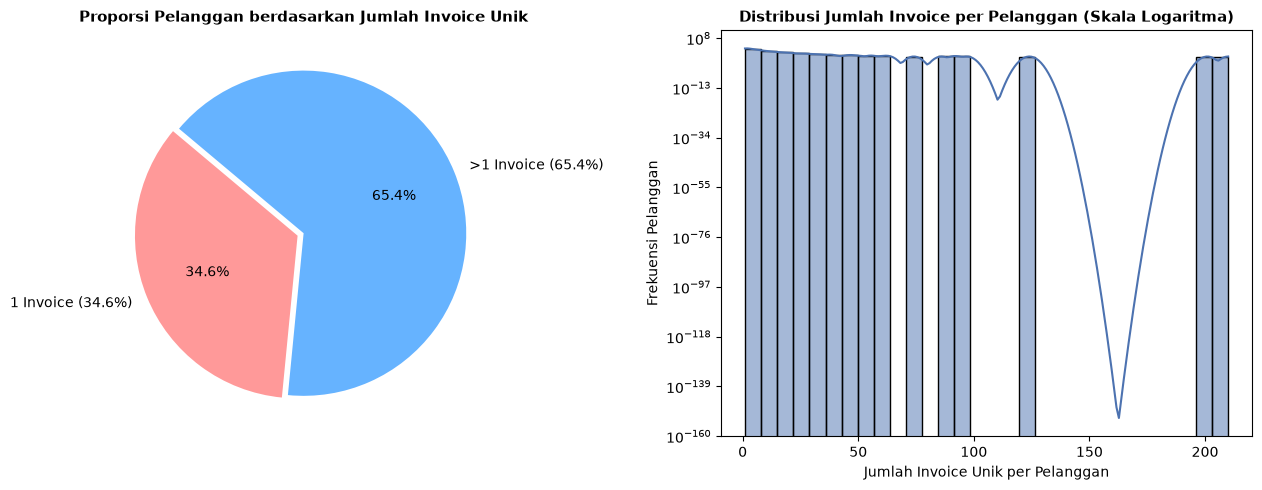

In [6]:
# Visualisasi EDA Jumlah Invoice per Pelanggan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].pie(
    [1500, 2839],
    labels=['1 Invoice (34.6%)', '>1 Invoice (65.4%)'],
    colors=['#ff9999','#66b3ff'],
    startangle=140,
    autopct='%1.1f%%',
    explode=(0.04, 0)
)
axes[0].set_title('Proporsi Pelanggan berdasarkan Jumlah Invoice Unik', fontsize=11, fontweight='bold')

sns.histplot(inv_per_cust, bins=30, kde=True, ax=axes[1], color='#4C72B0')
axes[1].set_title('Distribusi Jumlah Invoice per Pelanggan (Skala Logaritma)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Jumlah Invoice Unik per Pelanggan', fontsize=10)
axes[1].set_ylabel('Frekuensi Pelanggan', fontsize=10)
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

## Preprocessing Data

In [7]:
# Simpan statistik awal
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()
customers_before = df['CustomerID'].nunique()

# Preprocessing data
clean_df = df.copy()
clean_df['InvoiceNo'] = clean_df['InvoiceNo'].astype(str)
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'], errors='coerce')

# Clean missing, cancellation, & non-positive quantity
clean_df = clean_df.dropna(subset=['CustomerID', 'InvoiceDate', 'Description']).copy()
clean_df = clean_df[~clean_df['InvoiceNo'].str.startswith('C')].copy()
clean_df = clean_df[clean_df['Quantity'] > 0].copy()

# Harmonisasi InvoiceDate per InvoiceNo (penanganan mismatched timestamp/menit)
clean_df['InvoiceDate'] = clean_df.groupby('InvoiceNo')['InvoiceDate'].transform('min')

# Normalisasi tipe data
clean_df['CustomerID'] = clean_df['CustomerID'].astype('int64')
clean_df['Description'] = clean_df['Description'].astype(str).str.strip()
clean_df = clean_df[clean_df['Description'] != ''].copy()

rows_after = len(clean_df)
invoices_after = clean_df['InvoiceNo'].nunique()
customers_after = clean_df['CustomerID'].nunique()

comparison = pd.DataFrame({
    'Sebelum': [rows_before, invoices_before, customers_before],
    'Sesudah': [rows_after, invoices_after, customers_after]
}, index=['Jumlah baris', 'Jumlah invoice', 'Jumlah pelanggan'])

display(comparison)
print(f"Baris yang tersisa: {rows_after / rows_before:.2%} dari data awal")

,Sebelum,Sesudah
Jumlah baris,541909,397924
Jumlah invoice,25900,18536
Jumlah pelanggan,4372,4339


Baris yang tersisa: 73.43% dari data awal


In [8]:
# Bentuk itemset unik untuk setiap invoice milik pelanggan
invoice_itemsets = (
    clean_df.groupby(['CustomerID', 'InvoiceNo'], as_index=False)
    .agg(
        InvoiceDate=('InvoiceDate', 'min'),
        Items=('Description', lambda x: sorted(set(x)))
    )
)

# Urutkan invoice berdasarkan waktu transaksi per pelanggan
invoice_itemsets = invoice_itemsets.sort_values(
    ['CustomerID', 'InvoiceDate', 'InvoiceNo']
).reset_index(drop=True)

# Bentuk Sequence per pelanggan: List of Itemsets
customer_sequences = (
    invoice_itemsets.groupby('CustomerID')['Items']
    .apply(list)
    .to_dict()
)

sequences = list(customer_sequences.values())
print("Jumlah pelanggan / sequence:", len(sequences))
print("Contoh sequence pelanggan:")
for customer_id, sequence in islice(customer_sequences.items(), 3):
    print(f"CustomerID {customer_id} ({len(sequence)} invoice): {sequence[:2]}")

print("\nRata-rata jumlah invoice per pelanggan:",
      round(np.mean([len(seq) for seq in sequences]), 2))

Jumlah pelanggan / sequence: 4339
Contoh sequence pelanggan:
CustomerID 12346 (1 invoice): [['MEDIUM CERAMIC TOP STORAGE JAR']]
CustomerID 12347 (7 invoice): [['3D DOG PICTURE PLAYING CARDS', 'AIRLINE BAG VINTAGE JET SET BROWN', 'ALARM CLOCK BAKELIKE CHOCOLATE', 'ALARM CLOCK BAKELIKE GREEN', 'ALARM CLOCK BAKELIKE ORANGE', 'ALARM CLOCK BAKELIKE PINK', 'ALARM CLOCK BAKELIKE RED', 'BATHROOM METAL SIGN', 'BLACK CANDELABRA T-LIGHT HOLDER', 'BLACK EAR MUFF HEADPHONES', 'BLACK GRAND BAROQUE PHOTO FRAME', 'BLUE 3 PIECE POLKADOT CUTLERY SET', 'BLUE DRAWER KNOB ACRYLIC EDWARDIAN', 'BOOM BOX SPEAKER BOYS', 'BOX OF 6 ASSORTED COLOUR TEASPOONS', 'CAMOUFLAGE EAR MUFF HEADPHONES', 'CLEAR DRAWER KNOB ACRYLIC EDWARDIAN', 'COLOUR GLASS. STAR T-LIGHT HOLDER', 'EMERGENCY FIRST AID TIN', 'FOUR HOOK  WHITE LOVEBIRDS', 'GREEN DRAWER KNOB ACRYLIC EDWARDIAN', 'LARGE HEART MEASURING SPOONS', 'MINI PAINT SET VINTAGE', 'PINK 3 PIECE POLKADOT CUTLERY SET', 'PINK DRAWER KNOB ACRYLIC EDWARDIAN', 'PURPLE DRAWERKNOB A

# Modeling

In [9]:
MIN_SUPPORT = 0.01
MAX_PATTERN_LENGTH = 3

n_customers = len(sequences)
if n_customers == 0:
    raise ValueError("Tidak ada sequence pelanggan setelah preprocessing.")

min_support_count = int(np.ceil(MIN_SUPPORT * n_customers))
print("Jumlah pelanggan:", n_customers)
print("Minimum support:", MIN_SUPPORT)
print("Minimum jumlah pelanggan:", min_support_count)

def prefixspan_single_items(sequences, min_count, max_len=3):
    """PrefixSpan untuk pola item tunggal pada itemset berurutan."""
    patterns = []
    initial_projected = {sid: -1 for sid in range(len(sequences))}

    def grow(prefix, projected):
        if len(prefix) >= max_len:
            return

        extension_positions = defaultdict(dict)
        for sid, last_pos in projected.items():
            sequence = sequences[sid]
            for pos in range(last_pos + 1, len(sequence)):
                for item in set(sequence[pos]):
                    if sid not in extension_positions[item]:
                        extension_positions[item][sid] = pos

        frequent_extensions = [
            (item, positions)
            for item, positions in extension_positions.items()
            if len(positions) >= min_count
        ]

        for item, positions in frequent_extensions:
            new_prefix = prefix + (item,)
            support_count = len(positions)
            patterns.append({
                "pattern": new_prefix,
                "support_count": support_count,
                "support": support_count / len(sequences)
            })
            grow(new_prefix, positions)

    grow(tuple(), initial_projected)
    return pd.DataFrame(patterns)

patterns_df = prefixspan_single_items(
    sequences,
    min_count=min_support_count,
    max_len=MAX_PATTERN_LENGTH
)

print("Jumlah pola yang ditemukan:", len(patterns_df))
display(patterns_df.sort_values(
    ["support", "pattern"], ascending=[False, True]
).head(10))

Jumlah pelanggan: 4339
Minimum support: 0.01
Minimum jumlah pelanggan: 44
Jumlah pola yang ditemukan: 34732


,pattern,support_count,support
695,"(REGENCY CAKESTAND 3 TIER,)",881,0.203042
24370,"(WHITE HANGING HEART T-LIGHT HOLDER,)",856,0.197280
12527,"(PARTY BUNTING,)",708,0.163171
25412,"(ASSORTED COLOUR BIRD ORNAMENT,)",678,0.156257
3129,"(SET OF 3 CAKE TINS PANTRY DESIGN,)",640,0.147499
16383,"(JUMBO BAG RED RETROSPOT,)",635,0.146347
9970,"(PACK OF 72 RETROSPOT CAKE CASES,)",635,0.146347
30485,"(PAPER CHAIN KIT 50'S CHRISTMAS,)",613,0.141277
30957,"(NATURAL SLATE HEART CHALKBOARD,)",587,0.135285
5004,"(BAKING SET 9 PIECE RETROSPOT,)",581,0.133902


## Eval: Support, Confidence, dan Pemisahan Pola Multi-Item


In [10]:
# Lookup support untuk setiap pola
support_lookup = {
    row.pattern: row.support
    for row in patterns_df.itertuples(index=False)
}

def calculate_confidence(pattern):
    if len(pattern) < 2:
        return np.nan
    prefix = pattern[:-1]
    prefix_support = support_lookup.get(prefix)
    if prefix_support is None or prefix_support == 0:
        return np.nan
    return support_lookup[pattern] / prefix_support

patterns_df["Pola"] = patterns_df["pattern"].apply(lambda p: " → ".join(p))
patterns_df["Panjang_Pola"] = patterns_df["pattern"].apply(len)
patterns_df["Confidence"] = patterns_df["pattern"].apply(calculate_confidence)

results_all = patterns_df[
    ["Pola", "Panjang_Pola", "support_count", "support", "Confidence"]
].rename(columns={
    "support_count": "Jumlah pelanggan",
    "support": "Support"
}).sort_values(
    ["Support", "Confidence"], ascending=[False, False]
).reset_index(drop=True)

# Filter khusus pola berurutan multi-item (Panjang >= 2)
results_seq = results_all[results_all["Panjang_Pola"] >= 2].sort_values(
    ["Support", "Confidence"], ascending=[False, False]
).reset_index(drop=True)

print(f"Total seluruh pola: {len(results_all):,}")
print(f"Pola 1-itemset (produk populer): {(results_all['Panjang_Pola'] == 1).sum():,}")
print(f"Pola Sekuensial Multi-item (len >= 2): {len(results_seq):,}")
print("\nContoh Pola Sekuensial Multi-item (len >= 2):")
display(results_seq.head(10))

Total seluruh pola: 34,732
Pola 1-itemset (produk populer): 1,763
Pola Sekuensial Multi-item (len >= 2): 32,969

Contoh Pola Sekuensial Multi-item (len >= 2):


,Pola,Panjang_Pola,Jumlah pelanggan,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HAN...,2,405,0.093339,0.473131
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3...,2,330,0.076054,0.374574
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.071906,0.491339
3,ASSORTED COLOUR BIRD ORNAMENT → ASSORTED COLOU...,2,291,0.067066,0.429204
4,PARTY BUNTING → PARTY BUNTING,2,280,0.064531,0.395480
5,LUNCH BAG RED RETROSPOT → LUNCH BAG RED RETROSPOT,2,276,0.063609,0.518797
6,LUNCH BAG BLACK SKULL. → LUNCH BAG BLACK SKULL.,2,229,0.052777,0.500000
7,SET OF 3 CAKE TINS PANTRY DESIGN → SET OF 3 CA...,2,225,0.051855,0.351562
8,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HAN...,3,222,0.051164,0.548148
9,LUNCH BAG RED RETROSPOT → LUNCH BAG BLACK SKULL.,2,212,0.048859,0.398496


##  Top Pola Sekuensial dan Interpretasi Bisnis

In [11]:
top_3_seq = results_seq.head(3).copy()
display(top_3_seq)

print("=== Interpretasi Bisnis Ritel untuk Top 3 Pola Sekuensial Multi-Item ===\n")
for rank, (_, row) in enumerate(top_3_seq.iterrows(), start=1):
    items = row['Pola'].split(' → ')
    print(
        f"{rank}. Pola: {row['Pola']}\n"
        f"   Support: {row['Support']:.4f} ({row['Jumlah pelanggan']} pelanggan)\n"
        f"   Confidence: {row['Confidence']:.4f} ({row['Confidence']*100:.2f}%)\n"
        f"   Interpretasi Bisnis: Pelanggan yang membeli '{items[0]}' pada transaksi pertama "
        f"memiliki peluang sebesar {row['Confidence']*100:.1f}% untuk membeli '{items[1]}' "
        f"pada transaksi berikutnya di lain hari.\n"
    )

,Pola,Panjang_Pola,Jumlah pelanggan,Support,Confidence
0,WHITE HANGING HEART T-LIGHT HOLDER → WHITE HAN...,2,405,0.093339,0.473131
1,REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3...,2,330,0.076054,0.374574
2,JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT,2,312,0.071906,0.491339


=== Interpretasi Bisnis Ritel untuk Top 3 Pola Sekuensial Multi-Item ===

1. Pola: WHITE HANGING HEART T-LIGHT HOLDER → WHITE HANGING HEART T-LIGHT HOLDER
   Support: 0.0933 (405 pelanggan)
   Confidence: 0.4731 (47.31%)
   Interpretasi Bisnis: Pelanggan yang membeli 'WHITE HANGING HEART T-LIGHT HOLDER' pada transaksi pertama memiliki peluang sebesar 47.3% untuk membeli 'WHITE HANGING HEART T-LIGHT HOLDER' pada transaksi berikutnya di lain hari.

2. Pola: REGENCY CAKESTAND 3 TIER → REGENCY CAKESTAND 3 TIER
   Support: 0.0761 (330 pelanggan)
   Confidence: 0.3746 (37.46%)
   Interpretasi Bisnis: Pelanggan yang membeli 'REGENCY CAKESTAND 3 TIER' pada transaksi pertama memiliki peluang sebesar 37.5% untuk membeli 'REGENCY CAKESTAND 3 TIER' pada transaksi berikutnya di lain hari.

3. Pola: JUMBO BAG RED RETROSPOT → JUMBO BAG RED RETROSPOT
   Support: 0.0719 (312 pelanggan)
   Confidence: 0.4913 (49.13%)
   Interpretasi Bisnis: Pelanggan yang membeli 'JUMBO BAG RED RETROSPOT' pada transaksi

## Visualisasi Pola Berurutan Multi-Item

C:\Users\RYZEN\AppData\Local\Temp\ipykernel_5068\3654316464.py:16: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


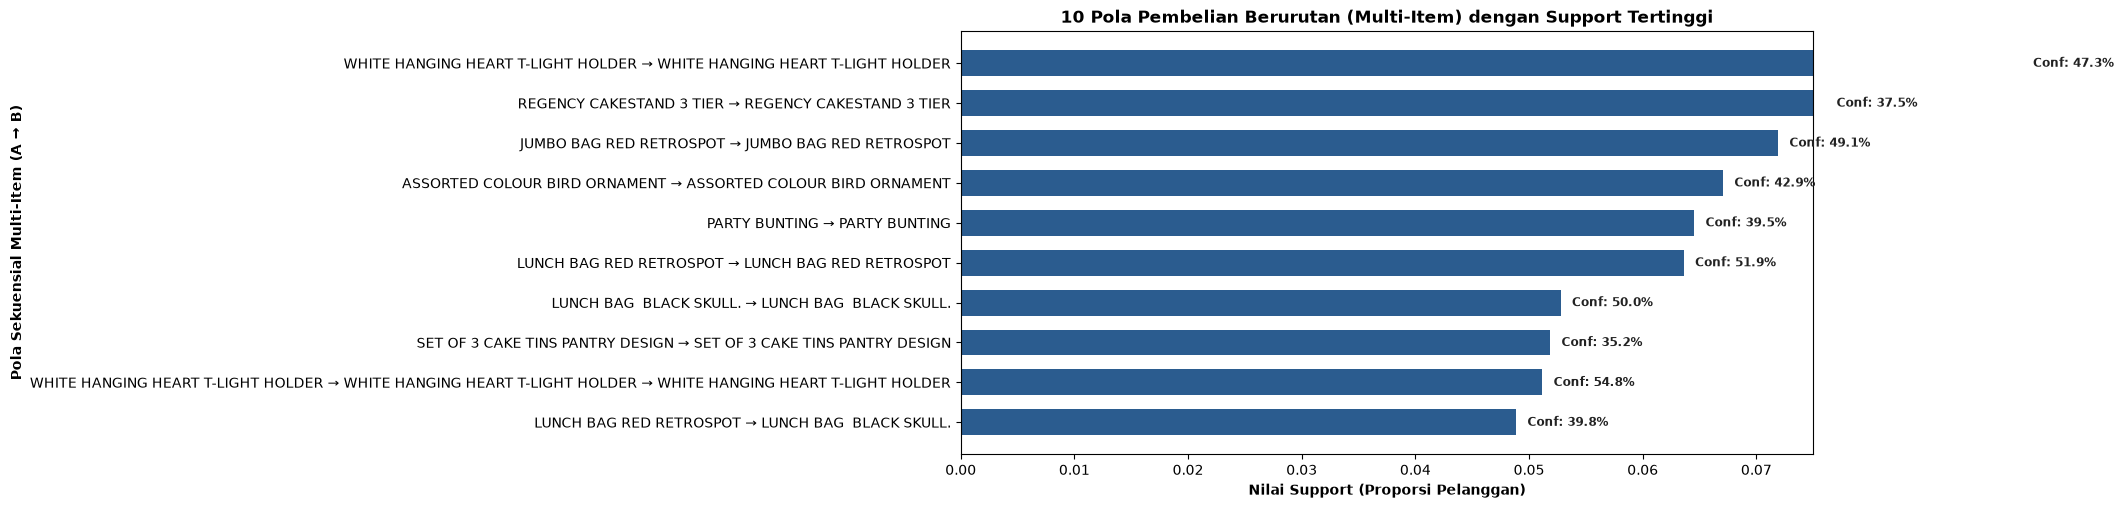

In [12]:
top_plot = results_seq.head(10).sort_values("Support")
if not top_plot.empty:
    fig, ax = plt.subplots(figsize=(11, 5.5))
    bars = ax.barh(top_plot["Pola"], top_plot["Support"], color='#2b5c8f', height=0.65)
    ax.set_xlabel("Nilai Support (Proporsi Pelanggan)", fontsize=10, fontweight='bold')
    ax.set_ylabel("Pola Sekuensial Multi-Item (A → B)", fontsize=10, fontweight='bold')
    ax.set_title("10 Pola Pembelian Berurutan (Multi-Item) dengan Support Tertinggi", fontsize=12, fontweight='bold')
    ax.set_xlim(0, 0.075)
    for bar, conf in zip(bars, top_plot['Confidence']):
        ax.text(
            bar.get_width() + 0.001,
            bar.get_y() + bar.get_height()/2,
            f"Conf: {conf*100:.1f}%",
            va='center', fontsize=8.5, color='#222222', fontweight='bold'
        )
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ada pola untuk divisualisasikan.")